# Getting started with R in EOxHub

This notebook demonstrates:
- filtering and summarizing tables with dplyr
- plotting with ggplot2
- reading and transforming vector data with sf
- creating and analyzing a raster with terra

Select the R kernel before running the cells.

### Load packages for tables, plots, vector data, and rasters.

In [1]:
suppressPackageStartupMessages({
  library(dplyr)
  library(ggplot2)
  library(sf)
  library(terra)
})

code for methods in class “Rcpp_SpatCategories” was not checked for suspicious field assignments (recommended package ‘codetools’ not available?)

code for methods in class “Rcpp_SpatCategories” was not checked for suspicious field assignments (recommended package ‘codetools’ not available?)

code for methods in class “Rcpp_SpatDataFrame” was not checked for suspicious field assignments (recommended package ‘codetools’ not available?)

code for methods in class “Rcpp_SpatDataFrame” was not checked for suspicious field assignments (recommended package ‘codetools’ not available?)

code for methods in class “Rcpp_SpatExtent” was not checked for suspicious field assignments (recommended package ‘codetools’ not available?)

code for methods in class “Rcpp_SpatExtent” was not checked for suspicious field assignments (recommended package ‘codetools’ not available?)

code for methods in class “Rcpp_SpatFactor” was not checked for suspicious field assignments (recommended package ‘codetools’ no

### Explore R’s built-in iris dataset and calculate averages by species.

In [2]:
head(iris)

summary_by_species <- iris |>
  group_by(Species) |>
  summarise(
    samples = n(),
    mean_petal_length = mean(Petal.Length),
    mean_petal_width = mean(Petal.Width),
    .groups = "drop"
  )

summary_by_species

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
1,5.1,3.5,1.4,0.2,setosa
2,4.9,3.0,1.4,0.2,setosa
3,4.7,3.2,1.3,0.2,setosa
4,4.6,3.1,1.5,0.2,setosa
5,5.0,3.6,1.4,0.2,setosa
6,5.4,3.9,1.7,0.4,setosa


Species,samples,mean_petal_length,mean_petal_width
<fct>,<int>,<dbl>,<dbl>
setosa,50,1.462,0.246
versicolor,50,4.260,1.326
virginica,50,5.552,2.026


### Filter flower measurements and compare species in a scatter plot.

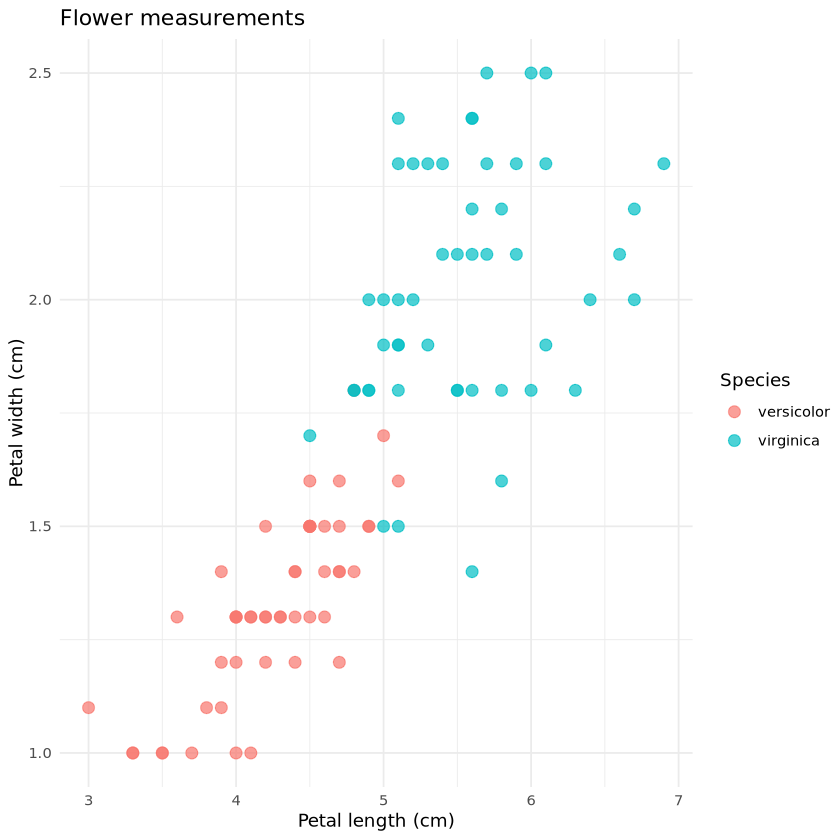

In [3]:
iris |>
  filter(Petal.Length > 2) |>
  ggplot(aes(
    x = Petal.Length,
    y = Petal.Width,
    colour = Species
  )) +
  geom_point(size = 3, alpha = 0.7) +
  labs(
    title = "Flower measurements",
    x = "Petal length (cm)",
    y = "Petal width (cm)"
  ) +
  theme_minimal()

### Read counties bundled with sf, reproject, and calculate their areas.

In [4]:
counties <- st_read(
  system.file("gpkg/nc.gpkg", package = "sf"),
  quiet = TRUE
) |>
  st_transform(5070)

counties$area_km2 <- as.numeric(st_area(counties)) / 1e6

counties |>
  st_drop_geometry() |>
  dplyr::select(NAME, area_km2) |>
  arrange(desc(area_km2)) |>
  head()

,NAME,area_km2
,<chr>,<dbl>
1,Columbus,2450.161
2,Robeson,2439.537
3,Sampson,2438.013
4,Bladen,2288.811
5,Wake,2194.572
6,Pender,2181.275


### Map the counties, coloured by area.

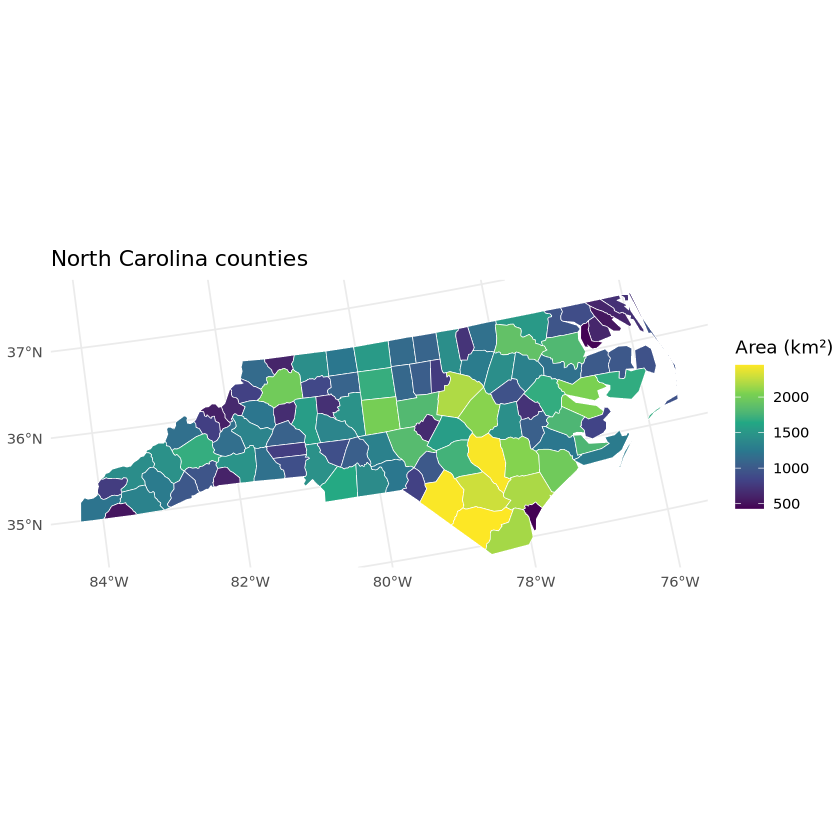

In [5]:
ggplot(counties) +
  geom_sf(aes(fill = area_km2), colour = "white", linewidth = 0.2) +
  scale_fill_viridis_c(name = "Area (km²)") +
  labs(title = "North Carolina counties") +
  theme_minimal()

### Convert R’s built-in volcano elevation matrix into a raster on a local 10 m grid.

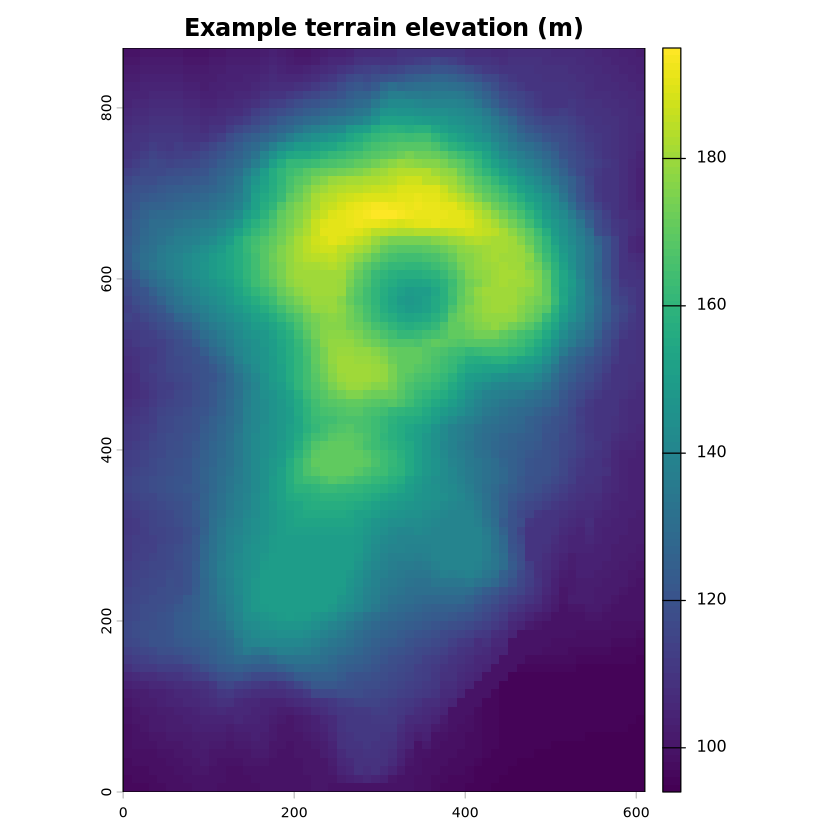

In [6]:
elevation <- rast(
  nrows = nrow(volcano),
  ncols = ncol(volcano),
  xmin = 0,
  xmax = ncol(volcano) * 10,
  ymin = 0,
  ymax = nrow(volcano) * 10,
  crs = ""
)

values(elevation) <- as.vector(t(volcano))
names(elevation) <- "elevation"

plot(elevation, main = "Example terrain elevation (m)")

### Summarize elevations and identify cells above 150 m.

,min,mean,max
,<dbl>,<dbl>,<dbl>
elevation,94,130.1879,195


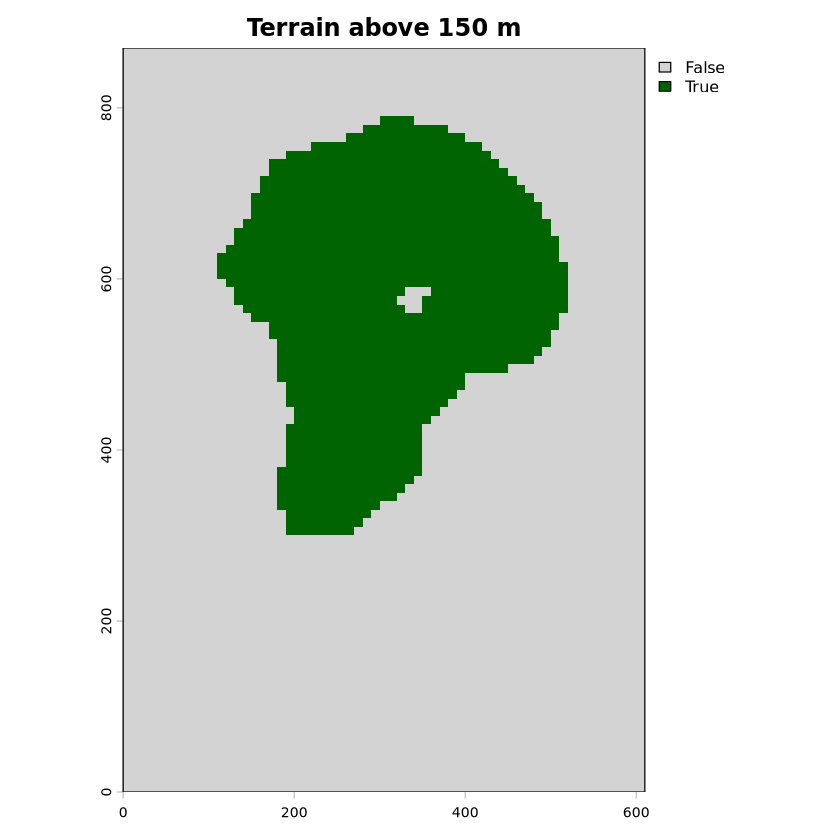

In [7]:
# Summarize elevation across the raster
global(elevation, fun = c("min", "mean", "max"), na.rm = TRUE)

# Identify cells higher than 150 metres
high_ground <- elevation > 150

plot(
  high_ground,
  main = "Terrain above 150 m",
  col = c("lightgrey", "darkgreen")
)

### Save the vector data as GeoPackage and the raster as GeoTIFF.

In [8]:
st_write(counties, "example_counties.gpkg", delete_dsn = TRUE, quiet = TRUE)

writeRaster(
  elevation,
  "example_elevation.tif",
  overwrite = TRUE
)